**Pre Trained ResNet34**

**Libraries**

In [1]:
import sys
from pathlib import Path

cloned_rep_path=r'C:\Users\laika\OneDrive\Documents\Capstone I All Files\Capstone-DATA4381'
sys.path.insert(0,cloned_rep_path)

from capstone_data.image_loader import load_dataset, split_dataset, load_arrays

from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import resnet34, ResNet34_Weights

from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

**Load Dataset**

In [5]:
# Dictionary to store the datasets

train_v1 = load_dataset('aug_data_v1', split='train')
val_v1 = load_dataset('aug_data_v1', split='validation')
test_v1 = load_dataset('aug_data_v1', split='test')

train_v3 = load_dataset('aug_data_v3', split='train')
val_v3 = load_dataset('aug_data_v3', split='validation')
test_v3 = load_dataset('aug_data_v3', split='test')

print(len(train_v1))
print(len(val_v1))
print(len(test_v1))

print(len(train_v3))
print(len(val_v3))
print(len(test_v3))

aug_dict={
    'aug_data_v1': {'train': train_v1, 'val': val_v1, 'test': test_v1},
    'aug_data_v3': {'train': train_v3, 'val': val_v3, 'test': test_v3}
}

14019
1662
1673
12047
1650
1646


In [6]:
class DataManger:
    def __init__(self, aug_dict, image_size=48, batch_size=32):
        self.aug_dict = aug_dict
        self.batch_size=batch_size
        self.transform = transforms.Compose([
            transforms.Grayscale(num_output_channels=3),
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
        ])
        
    def image_preprocessing(self):  
        train_proc = {} 
             
        for key, values in self.aug_dict.items():
            train_proc[key] = {} 
               
            for split, records in values.items():
                samples = []

                for record in records:
                    with Image.open(record["path"]) as image:
                        image_tensor = self.transform(image)

                    samples.append((image_tensor, record["label"]))

                train_proc[key][split] = DataLoader(
                    samples,
                    batch_size=self.batch_size,
                    shuffle=(split == "train"),
                )

        return train_proc
    
manage=DataManger(aug_dict)
load=manage.image_preprocessing()

train_new_v1=load['aug_data_v1']['train']
train_new_v3=load['aug_data_v3']['train']

test_new_v1=load['aug_data_v1']['test']
test_new_v3=load['aug_data_v3']['test']

val_new_v1=load['aug_data_v1']['val']
val_new_v3=load['aug_data_v3']['val']


In [7]:
# Datasets are now torch objects .dataset()

data_names=[train_new_v1, train_new_v3, test_new_v1, test_new_v3, val_new_v1, val_new_v3]
for i in data_names:
    print(f'Length of dataset {i}: {len(i.dataset)}')


Length of dataset <torch.utils.data.dataloader.DataLoader object at 0x0000027C8AE74830>: 14019
Length of dataset <torch.utils.data.dataloader.DataLoader object at 0x0000027C8B6656E0>: 12047
Length of dataset <torch.utils.data.dataloader.DataLoader object at 0x0000027C8B64DA90>: 1673
Length of dataset <torch.utils.data.dataloader.DataLoader object at 0x0000027C8AB031D0>: 1646
Length of dataset <torch.utils.data.dataloader.DataLoader object at 0x0000027C8B64D6D0>: 1662
Length of dataset <torch.utils.data.dataloader.DataLoader object at 0x0000027C8B665940>: 1650


In [8]:
# New dictionary to store the processed datasets
new_dict = {
    'aug_v1': {'train': train_new_v1, 'val': val_new_v1, 'test': test_new_v1},
    'aug_v3': {'train': train_new_v3, 'val': val_new_v3, 'test': test_new_v3}
}

**Modified Pre-trained ResNet34 model to handle FER-2013 images well**

weights=None --> Does not load pretrained ImageNet weights, because they were trained on large, colored images of everyday objects (224x224). This makes ResNet34 now learn features for FER-2013

conv1 (first layer) --> By default ResNet uses k=7, stride=2 (which immediately cuts down image size). Changing it to k=3 and stride=1 keeps the image at 48x48

maxpool--> Removed the default max pool latyer of stride 2. But because the images are already small (48,48) , that would shrink it down to (24,24), before modeling. So, no max pooling was used.

fc (final layer) --> ImageNet had 1000 output classes, here we are only using 3 (happy, sad, angry)



In [32]:
# Modified for 3 classes & 48x48 size

def modify_resnet34(num_classes=3):
    
    model=resnet34(weights=None) # No weights, since default weights expect 224x224 colored images
    
    model.conv1=nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False) # Modify the first layer for 48,48 images
    
    model.maxpool=nn.Identity() #  Remove maxpool layer, to avoid shrinking image features too much
    
    model.fc=nn.Linear(model.fc.in_features,num_classes) # Final layer
    
    return model

**First Version of ResNet34**

In [33]:

class ResNet34Trainer:
    def __init__(self, aug_dict, num_classes=3, lr=0.001, device=None):
        self.aug_dict=aug_dict
        self.num_classes=num_classes
        self.lr=lr
        if device is None:
            self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        else:
            self.device = device
        self.trained_versions={}
    
    def train_model(self,num_epochs=3):
        
        # Iterate through all versions
        for name, data in self.aug_dict.items():
            print(f'Training: {name}')
            
            model=modify_resnet34(num_classes=self.num_classes).to(self.device)
            
            # Loss function
            criterion=nn.CrossEntropyLoss()
            # Optimizer
            optimizer=optim.Adam(model.parameters(), lr=self.lr)
            
            train_data=data['train']
            
            # Epochs
            for epoch in range(num_epochs):
                model.train()
                total_loss=0.0 #total loss per batch
                
                for images,labels in train_data:
                    
                    # Ensure images and labels are both on either CPU or GPU
                    images,labels=images.to(self.device),labels.to(self.device)
                    
                    # Add up gradients from previous step
                    optimizer.zero_grad()
                    
                    # Forward pass
                    outputs=model(images)
                    
                    # Compute loss (Compare model's predions with the true labels)
                    loss=criterion(outputs, labels)

                    # Backpropagation
                    loss.backward()
                    
                    # Update weights
                    optimizer.step()
                    
                    total_loss+=loss.item()
                
                avg_loss=total_loss/len(train_data)
                print(f'Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss}')
                # check test/val loss
                
                # val_data=data['val']
                
            # Store model version
            self.trained_versions[name]=model
            print(f'Training completed for {name}')
            
        return self.trained_versions
    
    def evalute_model(self, eval_data, model):
        model.eval() # Set model to evaluation mode
        all_pred=[]
        all_labels=[]
        
        with torch.no_grad():
            for image, label in eval_data:
                image = image.to(self.device) # Store images to selected device
                label = label.to(self.device)
                
                image_out=model(image)
                
                _, pred_class = torch.max(image_out, 1) # Get the predicted class label
                
                all_pred.extend(pred_class.cpu().numpy())
                all_labels.extend(label.cpu().numpy()) # Move labels to CPU & convert to numpy
        
        # Metrics
        accuracy = accuracy_score(all_labels, all_pred)
        precision, recall, f1, _ = precision_recall_fscore_support(
            all_labels, all_pred, average='macro', zero_division=0
        )
        metric_dict={
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1_macro': f1
        }
        return metric_dict, all_pred, all_labels

In [36]:
# Call Class

train=ResNet34Trainer(new_dict, num_classes=3, lr=0.001)
trained_models=train.train_model(num_epochs=3)

Training: aug_v1
Epoch 1/3, Loss: 0.8831454534465468
Epoch 2/3, Loss: 0.640621641298633
Epoch 3/3, Loss: 0.5561577998152626
Training completed for aug_v1
Training: aug_v3
Epoch 1/3, Loss: 0.9249534274918331
Epoch 2/3, Loss: 0.6803236248006239
Epoch 3/3, Loss: 0.5840119809623738
Training completed for aug_v3


In [ ]:
#---------Conf matrix and score table and epoch by val by loss graph here---------For ResNet34Trainer-------#

In [58]:
print(trained_models['aug_v1'])
print(trained_models['aug_v3'])

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(

In [70]:
base_results_test={}

for name, split in trained_models.items():
    eval_data_test=new_dict[name]['test']
    
    metrics, preds, labels = train.evalute_model(eval_data_test, split)
    base_results_test[name]={
            'metrics': metrics,
            'preds': preds,
            'labels': labels
    }
    

In [71]:
print(base_results_test['aug_v1']['metrics'])
print(base_results_test['aug_v3']['metrics'])


{'accuracy': 0.8302450687387926, 'precision': 0.7025184980999004, 'recall': 0.6979602861093149, 'f1_macro': 0.6983849600526303}
{'accuracy': 0.8256379100850547, 'precision': 0.7098272498798172, 'recall': 0.7422634534756126, 'f1_macro': 0.7213939830267119}


In [94]:
class Visualizations:
    def __init__(self):
        pass
    
    def conf_matrix(self, name, all_labels, all_pred, plot_labels=None, normalize='true'): # y=all_labels, x=all_pred
        
        cm = confusion_matrix(all_labels, all_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd')
        plt.title(f'Confusion Matrix of {name}')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')
        plt.tight_layout()
        plot=plt.show()
        
        return plot
    
    def metric_table(self, name, all_labels, all_pred):
        accuracy = accuracy_score(all_labels, all_pred)
        precision, recall, f1, _ = precision_recall_fscore_support(
                    all_labels, all_pred, average='macro', zero_division=0
                )
        metric_dict={
            'accuracy': [accuracy], # Wrap into lists for DataFrame
            'precision': [precision],        
            'recall': [recall],       
            'f1_macro': [f1]               
        }        
        df=pd.DataFrame(metric_dict)
        
        return df

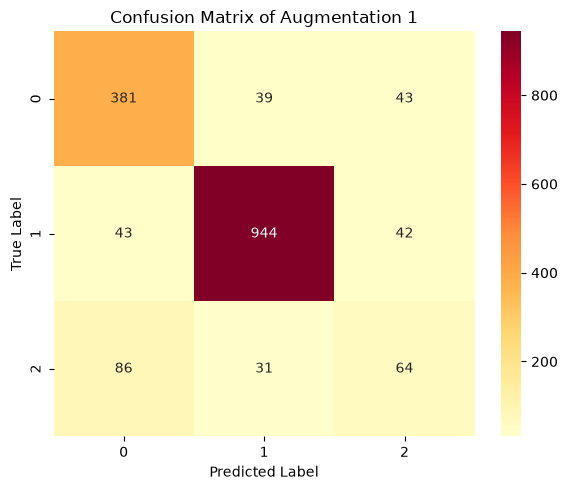

,accuracy,precision,recall,f1_macro
0,0.830245,0.702518,0.69796,0.698385


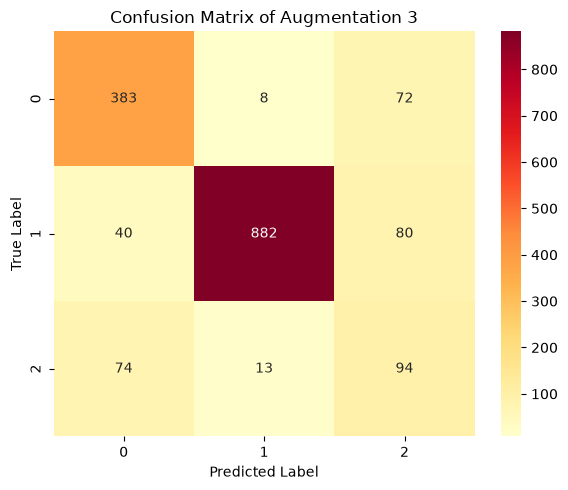

,accuracy,precision,recall,f1_macro
0,0.825638,0.709827,0.742263,0.721394


In [95]:
visual=Visualizations()
cm_base_v1=visual.conf_matrix(
    'Augmentation 1',
    base_results_test['aug_v1']['labels'],
    base_results_test['aug_v1']['preds'],
)
metrics_base_v1=visual.metric_table(
    'Augmentation 1',
    base_results_test['aug_v1']['labels'],
    base_results_test['aug_v1']['preds'],
)
display(metrics_base_v1)
cm_base_v3=visual.conf_matrix(
    'Augmentation 3',
    base_results_test['aug_v3']['labels'],
    base_results_test['aug_v3']['preds'],
)
metrics_base_v3=visual.metric_table(
    'Augmentation 3',
    base_results_test['aug_v3']['labels'],
    base_results_test['aug_v3']['preds'],
)
display(metrics_base_v3)

**Final ResNet34 Model**

In [2]:
# Modified for 3 classes & 48x48 size
# .Linear -->  for the output, output=inputxweight^T+bias

def modify_final_resnet34(num_classes=3):
    
    model=resnet34(weights=None) # No weights, since default weights expect 224x224 colored images
    
    model.conv1=nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False) # Modify the first layer for 48,48 images
    
    model.maxpool=nn.Identity() #  Remove maxpool layer, to avoid shrinking image features too much
    
    model.fc=(
        # nn.Dropout(0.5), #randomly turn off neurons to prevent overfitting
        nn.Linear(model.fc.in_features,num_classes)
        ) # Final layer
    
    return model

CrossEntropyLoss--> automatically applies softmax probabilityies is cross entropy loss
Relu--> is inside the resnet blocks (introduces non lienarity), allowing model to learn complex curves

In [23]:

class ResNet34:
    def __init__(self, aug_dict, num_classes=3, device=None):
        self.aug_dict=aug_dict
        self.num_classes=num_classes
        if device is None:
            self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        else:
            self.device = device
        self.trained_versions={}
    
    def train_model(self,num_epochs=3, lr=0.001, early_stop=5):
        
        # Iterate through all versions
        for name, data in self.aug_dict.items():
            print(f'Training: {name}, Learning rate: {lr}, Epochs: {num_epochs}')
            
            model=modify_final_resnet34(num_classes=self.num_classes).to(self.device)
            
            # Loss function
            criterion=nn.CrossEntropyLoss()
            # Optimizer
            optimizer=optim.Adam(model.parameters(), lr=lr)
            
            train_data=data['train']
            val_data=data['val']
            
            # Data
            best_f1 = 0.0
            best_model_state = None
            
            early_stopping= 0
            
            history={
                'loss': [],
                'val_loss':[],
                'val_f1': [],
                'best_f1':[]
            }
            
            # Epochs
            for epoch in range(num_epochs):
                model.train()
                total_loss = 0.0 #total loss per batch
                
                for images, labels in train_data:
                    
                    # Ensure images and labels are both on either CPU or GPU
                    images, labels=images.to(self.device),labels.to(self.device)
                    
                    # Add up gradients from previous step
                    optimizer.zero_grad()
                    
                    # Forward pass
                    outputs=model(images)
                    
                    # Compute loss (Compare model's predions with the true labels)
                    loss=criterion(outputs, labels)

                    # Backpropagation
                    loss.backward()
                    
                    # Update weights
                    optimizer.step()
                    
                    total_loss+=loss.item()
                
                avg_loss=total_loss/len(train_data)
                                
                # Evaluate on validation set every multiple of 5 epoch or on the very last epoch
                # if ((epoch+1) % 5 == 0) or (epoch == epoch - 1):
                
                
                val_loss, val_metrics, _, _= self.evaluate_model(val_data, model)
                    

                if val_metrics['f1_macro']> best_f1:
                    best_f1 = val_metrics['f1_macro']
                    best_model_state = model.state_dict() #keep copy of models weights
                    early_stopping=0 #reset counter since it imporoved
                else:
                    early_stopping+=1
                    
                history['loss'].append(avg_loss)
                history['val_loss'].append(val_loss)  
                history['val_f1'].append(val_metrics['f1_macro'])
                history['best_f1'].append(best_f1)
                
                print(f'Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss}')

                if early_stopping>=early_stop:
                    print('Stopped No Improvement!')
                    break
            # Load best weights back into model before saving
                
            if best_model_state is not None:
                model.load_state_dict(best_model_state)
                
            # Store model version
            self.trained_versions[name]={
                'model': model,
                'history': history
            }
            print(f'Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss}, Current F1: {val_metrics["f1_macro"]}, Best F1: {best_f1}')
            
        return self.trained_versions
    
    def evaluate_model(self, eval_data, model):
        model.eval() # Set model to evaluation mode
        criterion = nn.CrossEntropyLoss() # To calculate loss
        
        total_loss= 0.0
        all_pred=[]
        all_labels=[]
        
        with torch.no_grad():
            for image, label in eval_data:
                image = image.to(self.device) # Store images to selected device
                label = label.to(self.device)
                
                image_out=model(image)
                
                loss = criterion(image_out, label) #calculate validation loss
                total_loss += loss.item()
                
                _, pred_class = torch.max(image_out, 1) # Get the predicted class label
                
                all_pred.extend(pred_class.cpu().numpy())
                all_labels.extend(label.cpu().numpy()) # Move labels to CPU & convert to numpy
                
        # Calculate average validation loss
        avg_val_loss = total_loss / len(eval_data)
        
        # Metrics
        accuracy = accuracy_score(all_labels, all_pred)
        precision, recall, f1, _ = precision_recall_fscore_support(
            all_labels, all_pred, average='macro', zero_division=0
        )
        metric_dict={
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1_macro': f1
        }
        return avg_val_loss, metric_dict, all_pred, all_labels

In [26]:
final=ResNet34(aug_dict=new_dict, num_classes=3, device=None)

learning_rates=[0.001]

model_rates={}

for i in learning_rates:
    final_train=final.train_model(num_epochs=30, lr=i)
    

    for name, split in final_train.items():
        
        data_test=new_dict[name]['test']
        
        # Create a unique key to combine the augmentation name and learning rate version
        dict_key=f'{name}_lr_{i}'
        _,metrics, preds, labels = final.evaluate_model(data_test, split['model'])
        
        # Store each model
        model_rates[dict_key]={
                'augmentation': name,
                'learning_rate':i,
                'metrics': metrics,
                'preds': preds,
                'labels': labels,
                'split_types': split,
                'model': split['model'],
                'history': split['history']
        }
        
    
    

Training: aug_v1, Learning rate: 0.001, Epochs: 30
Epoch 1/30, Loss: 0.939959094980583
Epoch 2/30, Loss: 0.6976943801502975
Epoch 3/30, Loss: 0.5822926724079258
Epoch 4/30, Loss: 0.5139145767295008
Epoch 5/30, Loss: 0.4628478218981644
Epoch 6/30, Loss: 0.40728504287083217
Epoch 7/30, Loss: 0.3666146978023112
Epoch 8/30, Loss: 0.3119655226257572
Epoch 9/30, Loss: 0.2601971016657923
Epoch 10/30, Loss: 0.218574680727408
Epoch 11/30, Loss: 0.18009238351976545
Epoch 12/30, Loss: 0.1552730872113351
Epoch 13/30, Loss: 0.10154819278712629
Epoch 14/30, Loss: 0.09691787149453777
Epoch 15/30, Loss: 0.06096389031299954
Epoch 16/30, Loss: 0.06786353818877072
Epoch 17/30, Loss: 0.06502373097119704
Epoch 18/30, Loss: 0.04354226653635712
Epoch 19/30, Loss: 0.047654654001997435
Epoch 20/30, Loss: 0.07050556637219987
Epoch 21/30, Loss: 0.04218396418401759
Epoch 22/30, Loss: 0.03507927330826029
Epoch 23/30, Loss: 0.047434279055001555
Epoch 24/30, Loss: 0.020280696895381367
Epoch 25/30, Loss: 0.0311710451

In [31]:
print(model_rates)

{'aug_v1_lr_0.001': {'augmentation': 'aug_v1', 'learning_rate': 0.001, 'metrics': {'accuracy': 0.8141063956963539, 'precision': 0.7244061056982276, 'recall': 0.733942435322762, 'f1_macro': 0.7023367277608945}, 'preds': [np.int64(0), np.int64(2), np.int64(0), np.int64(2), np.int64(2), np.int64(2), np.int64(0), np.int64(2), np.int64(0), np.int64(2), np.int64(0), np.int64(0), np.int64(2), np.int64(0), np.int64(0), np.int64(2), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(2), np.int64(2), np.int64(0), np.int64(2), np.int64(2), np.int64(1), np.int64(0), np.int64(2), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(2), np.int64(2), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(2), np.int64(2), np.int64(2), np.int64(0), np.int64(2), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(2), np.int64(2), np.int64(0), np.int64(0), np.int64(1), np.int64(2), np.int64(2), np.int64(0), np.int64(2), np.int64(0), 

In [51]:
class Visualizations:
    def __init__(self):
        pass
    
    def conf_matrix(self, name, all_labels, all_pred, plot_labels=['angry', 'happy', 'sad'], normalize='true'): # y=all_labels, x=all_pred
        
        cm = confusion_matrix(all_labels, all_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd', xticklabels=plot_labels, yticklabels=plot_labels)
        plt.title(f'Confusion Matrix of {name}')
        plt.ylabel('True Label')
        plt.xlabel('Predicted Label')
        plt.tight_layout()
        plot=plt.show()
        
        return plot
    
    def metric_table(self, name, all_labels, all_pred):
        accuracy = accuracy_score(all_labels, all_pred)
        precision, recall, f1, _ = precision_recall_fscore_support(
                    all_labels, all_pred, average='macro', zero_division=0
                )
        metric_dict={
            'accuracy': [accuracy], # Wrap into lists for DataFrame
            'precision': [precision],        
            'recall': [recall],       
            'f1_macro': [f1]               
        }        
        df=pd.DataFrame(metric_dict)
        
        
        return df
    
    def loss_graph(self, name, history):
        epochs = range(1, len(history['loss']) + 1)
        
        plt.figure(figsize=(14, 5))
        
        # Loss Curve
        plt.subplot(1, 2, 1)
        plt.plot(epochs, history['loss'], label='Training Loss', color='blue')
        plt.plot(epochs, history['val_loss'], label='Validation Loss', color='orange')
        plt.title(f'Loss Curve: {name}')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.legend()
        
        # F1 Score Curve
        plt.subplot(1, 2, 2)
        plt.plot(epochs, history['val_f1'], label='Validation Macro F1', color='green')
        plt.plot(epochs, history['best_f1'], label='Best F1 Record', linestyle='--', color='red')
        plt.title(f'F1 Score Curve: {name}')
        plt.xlabel('Epochs')
        plt.ylabel('Macro F1')
        plt.legend()
        
        plt.tight_layout()
        plt.show()

In [34]:
print(model_rates.keys())

dict_keys(['aug_v1_lr_0.001', 'aug_v3_lr_0.001'])


In [ ]:
print(model_rates.values())

For aug_v1_lr_0.001


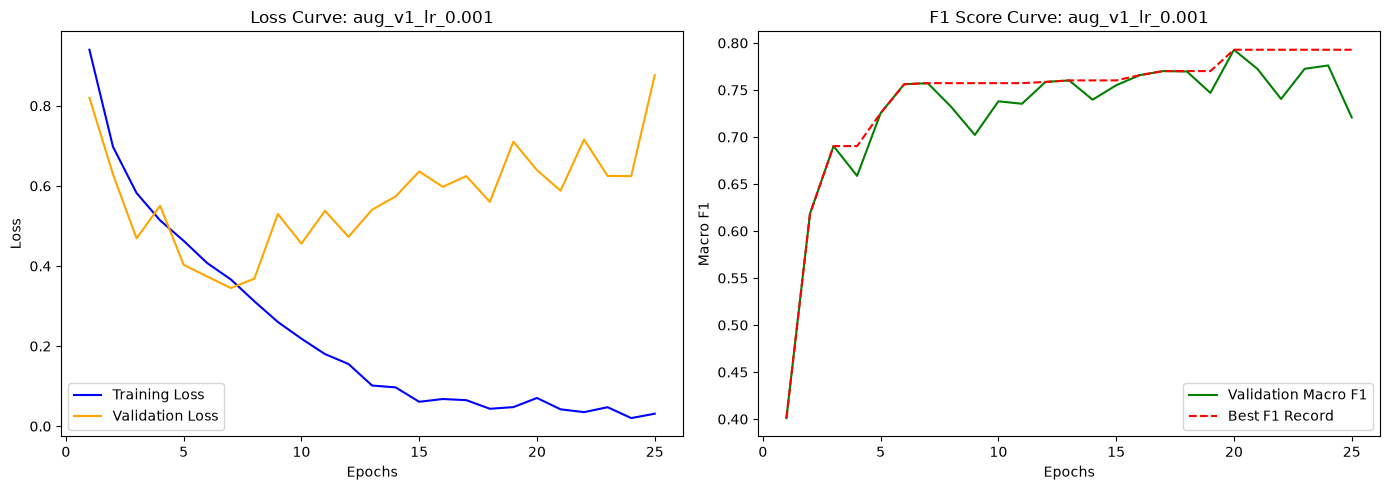

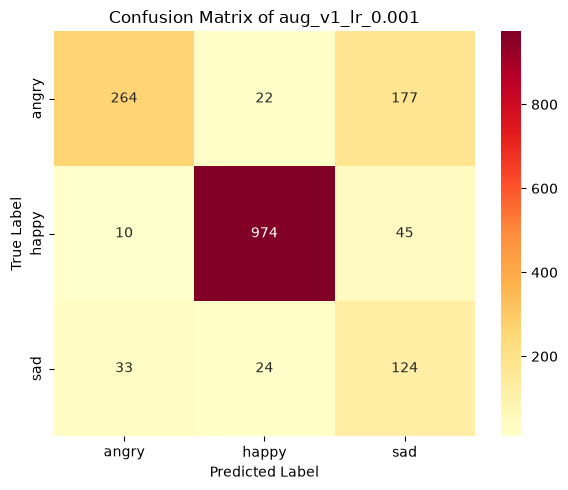

,accuracy,precision,recall,f1_macro
0,0.814106,0.724406,0.733942,0.702337


For aug_v3_lr_0.001


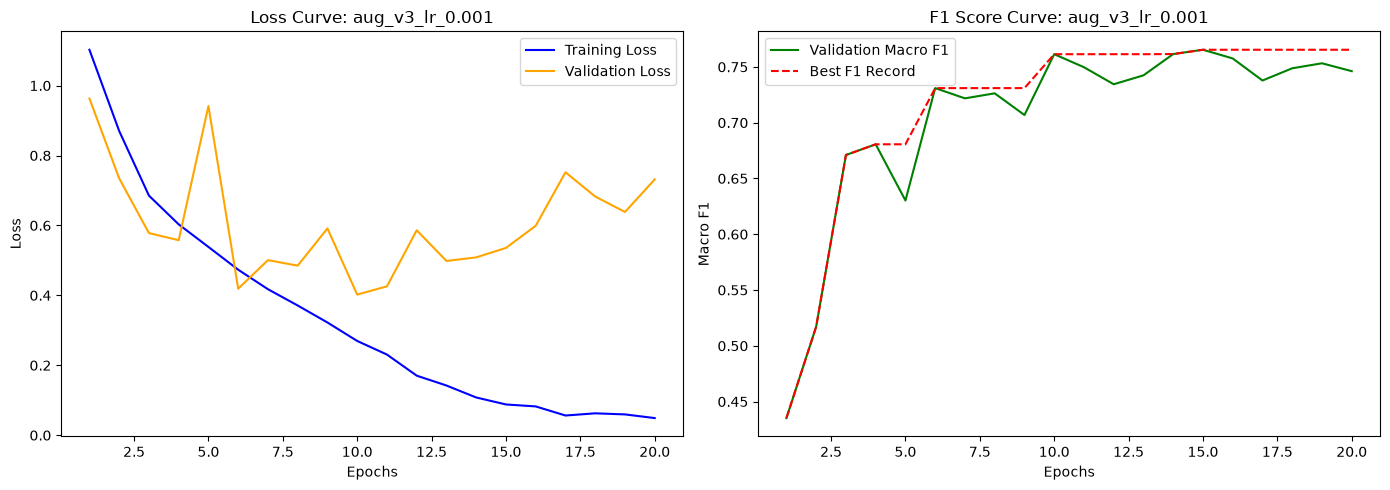

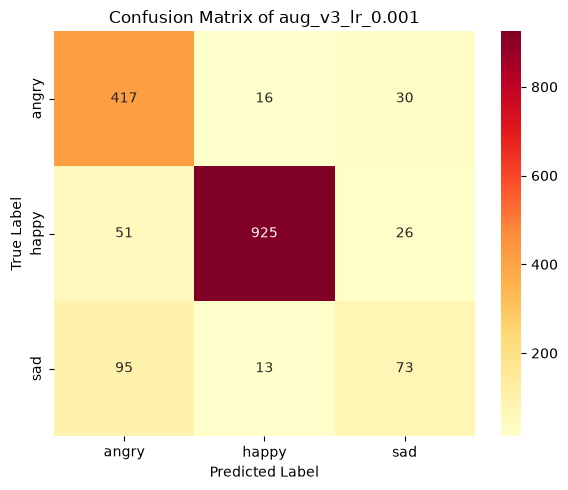

,accuracy,precision,recall,f1_macro
0,0.85966,0.758723,0.742372,0.743214


In [59]:
final_visuals=Visualizations()

for dict_key, data in model_rates.items():
    print(f'For {dict_key}')
    
    final_visuals.loss_graph(dict_key, data['history'])
    table=final_visuals.metric_table(dict_key, data['labels'], data['preds'])
    final_visuals.conf_matrix(dict_key, data['labels'], data['preds'])
    
    display(table)
    